# Full BERT — Interaction + Spread

Classify relationships among retrieved documents into five CONFLICTS categories using question–document representations from `bert-base-uncased`. Each question–document pair is encoded separately with a 512-token maximum.

**Architecture:** A Transformer encoder models interactions among retrieved document representations. The classifier combines their mean representation and element-wise max–min spread.

**Model settings:** `USE_INTERACTION=True`, `USE_SPREAD=True`. All four BERT variants share the same data split, input processing, optimizer, and training budget.

**Data:** `conflicts_621.jsonl` with the shared `conflicts_original_eval_split.json` manifest. Training uses 481 records (318 original and 163 synthetic); Validation uses 68 original records; Test uses 72 original records.

**Training:** Five-class, train-count-balanced CrossEntropy loss; learning rate `1e-5`; batch size 1; gradient accumulation 4; maximum 8 epochs; early-stopping patience 3; independent training seeds 42, 43, and 44.

**Model selection:** Save the highest **four-class Validation Macro-F1**, averaged over labels 0–3. Misinformation (label 4) is excluded only from that average; the model still trains and predicts all five classes. Test labels are not used to select checkpoints.

**Evaluation:** Report Test accuracy, five-class and four-class Macro-F1, per-class precision/recall/F1/support, confusion matrices, and mean ± SD over three seeds. The original Misinformation class has one validation example and one test example, so its class-specific performance has high uncertainty.


In [1]:
# Input and output directories for local and Kaggle execution
from pathlib import Path
import os

IS_KAGGLE = Path("/kaggle/input").is_dir()
if IS_KAGGLE:
    # Kaggle input mount may be /kaggle/input/conflicts or /kaggle/input/datasets/<owner>/conflicts.
    # Discover one dataset containing BOTH frozen files, without hardcoding an account name.
    matching_dirs = sorted({
        p.parent for p in Path("/kaggle/input").rglob("conflicts_621.jsonl")
        if (p.parent / "conflicts_original_eval_split.json").is_file()
    })
    if len(matching_dirs) != 1:
        raise FileNotFoundError(
            f"Expected exactly one Kaggle dataset with both frozen files; found {matching_dirs}. "
            "Attach your private 'conflicts' dataset using Kaggle Add Input."
        )
    DATA_DIR = matching_dirs[0]
    OUTPUT_DIR = Path("/kaggle/working")
else:
    DATA_DIR = Path.cwd()
    OUTPUT_DIR = Path.cwd()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(OUTPUT_DIR)  # Write checkpoints and CSV files to the output directory
print("Input directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)

import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.nn import CrossEntropyLoss

from transformers import BertTokenizer, BertModel

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight


Input directory: /kaggle/input/datasets/xiaominguo0222/conflicts
Output directory: /kaggle/working


## 1. Reproducibility and device


In [2]:
SEED = 42  # Initial random seed; training repeats with seeds 42, 43, and 44.

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [3]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


## 2. Load classification data

Load `conflicts_621.jsonl` and preserve the record order specified by `conflicts_original_eval_split.json`. Dataset labels map to integers 0–4.


In [4]:
# Read records in the order referenced by the fixed split manifest.
DATA_PATH = str(DATA_DIR / "conflicts_621.jsonl")
with open(DATA_PATH, "r", encoding="utf-8") as f:
    data = [json.loads(line) for line in f if line.strip()]

assert len(data) == 621, f"Expected 621 examples, found {len(data)}"
print("Loaded frozen dataset:", DATA_PATH)
print("Total examples:", len(data))

Loaded frozen dataset: /kaggle/input/datasets/xiaominguo0222/conflicts/conflicts_621.jsonl
Total examples: 621


In [5]:
print(data[0].keys())
print()

print("Question:")
print(data[0]["question"])

print("\nConflict type:")
print(data[0]["conflict_type"])

print("\nNumber of search results:")
print(len(data[0]["search_results"]))

dict_keys(['question', 'search_results', 'conflict_type'])

Question:
who is commander chief of the military

Conflict type:
Complementary information

Number of search results:
10


### Inspect an example


In [6]:
example_doc = data[0]["search_results"][0]

print("Document keys:")
print(example_doc.keys())

print("\nTitle:")
print(example_doc["title"])

print("\nShort text:")
print(example_doc["short_text"])

Document keys:
dict_keys(['title', 'short_text'])

Title:
Commander-in-chief - Wikipedia

Short text:
Accordingly, the Monarch is commander-in-chief of the Norwegian Armed Forces, and serves as chief diplomatic official abroad and as a symbol of unity.
 The President of the Republic, for a period of war, shall appoint the Commander-in-Chief of the Armed Forces on request of the Prime Minister. He may dismiss the Commander-in-Chief of the Armed Forces in accordance with the same procedure. The authority of the Commander-in-Chief of the Armed Forces, as well as the principle of his subordination to the constitutional organs of the Republic of Poland, shall be specified by statute.
 In the Portuguese military parlance, the term "Commander-in-Chief" (in Portuguese: comandante-em-chefe or simply comandante-chefe) refers to the unified military commander of all the land, naval and air forces in a theater of operations.
 Rwanda
Saudi Arabia
Article 60 of the Basic Law of Saudi Arabia states: 

### Five conflict categories


In [7]:
label2id = {
    "No conflict": 0,
    "Complementary information": 1,
    "Conflicting opinions and research outcomes": 2,
    "Conflict due to outdated information": 3,
    "Conflict due to misinformation": 4,
}

id2label = {
    0: "No Conflict",
    1: "Complementary",
    2: "Conflicting Opinions",
    3: "Outdated",
    4: "Misinformation",
}

labels = [item["conflict_type"] for item in data]

print(pd.Series(labels).value_counts())

No conflict                                   161
Complementary information                     115
Conflicting opinions and research outcomes    115
Conflict due to misinformation                115
Conflict due to outdated information          115
Name: count, dtype: int64


## 3. Model inputs and architecture

Each retrieved document is encoded jointly with the question (up to 512 tokens). A Transformer encoder models interactions among retrieved document representations. The classifier combines their mean representation and element-wise max–min spread. The classifier outputs five logits, one per conflict category.


In [8]:
MODEL_NAME = "bert-base-uncased"
tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)
MAX_LENGTH = 512


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [9]:
# Build one document text. Snippet, source and response_str are not used.
def build_document_text(doc):
    title = doc.get("title", "") or ""
    short_text = doc.get("short_text", "") or ""
    return "Title: " + title + ". Text: " + short_text if short_text else "Title: " + title


In [10]:
# Quick check of one question-document pair
example_question = data[0]["question"]
example_text = build_document_text(data[0]["search_results"][0])
encoding = tokenizer(example_question, example_text, truncation="only_second", max_length=MAX_LENGTH)
print("Question:", example_question)
print("\nDocument:", example_text[:1500])
print("\nToken count:", len(encoding["input_ids"]))


Question: who is commander chief of the military

Document: Title: Commander-in-chief - Wikipedia. Text: Accordingly, the Monarch is commander-in-chief of the Norwegian Armed Forces, and serves as chief diplomatic official abroad and as a symbol of unity.
 The President of the Republic, for a period of war, shall appoint the Commander-in-Chief of the Armed Forces on request of the Prime Minister. He may dismiss the Commander-in-Chief of the Armed Forces in accordance with the same procedure. The authority of the Commander-in-Chief of the Armed Forces, as well as the principle of his subordination to the constitutional organs of the Republic of Poland, shall be specified by statute.
 In the Portuguese military parlance, the term "Commander-in-Chief" (in Portuguese: comandante-em-chefe or simply comandante-chefe) refers to the unified military commander of all the land, naval and air forces in a theater of operations.
 Rwanda
Saudi Arabia
Article 60 of the Basic Law of Saudi Arabia state

In [11]:
# Check document truncation
truncation_records = []
special_tokens = tokenizer.num_special_tokens_to_add(pair=True)

for example_id, item in enumerate(data):
    question = item["question"]
    question_ids = tokenizer.encode(question, add_special_tokens=False)

    for doc_id, doc in enumerate(item["search_results"]):
        document_text = build_document_text(doc)
        document_ids = tokenizer.encode(document_text, add_special_tokens=False)

        full_length = len(question_ids) + len(document_ids) + special_tokens
        available_document_tokens = MAX_LENGTH - len(question_ids) - special_tokens
        truncated_tokens = max(0, len(document_ids) - available_document_tokens)

        truncation_records.append({
            "example_id": example_id,
            "doc_id": doc_id,
            "label": item["conflict_type"],
            "question": question,
            "full_length": full_length,
            "document_tokens": len(document_ids),
            "truncated_tokens": truncated_tokens,
            "is_truncated": truncated_tokens > 0
        })

truncation_df = pd.DataFrame(truncation_records)

total_docs = len(truncation_df)
truncated_docs = truncation_df["is_truncated"].sum()

print("Total documents:", total_docs)
print("Truncated documents:", truncated_docs)
print("Truncation rate:", round(truncated_docs / total_docs * 100, 2), "%")

print("\nToken length summary:")
print(truncation_df["full_length"].describe())

print("\nTruncation by class:")
print(
    truncation_df.groupby("label")["is_truncated"]
    .agg(["count", "sum", "mean"])
    .rename(columns={"count": "documents", "sum": "truncated", "mean": "truncation_rate"})
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (518 > 512). Running this sequence through the model will result in indexing errors


Total documents: 5677
Truncated documents: 8
Truncation rate: 0.14 %

Token length summary:
count    5677.000000
mean      323.610534
std       143.354736
min        14.000000
25%       235.000000
50%       389.000000
75%       436.000000
max       558.000000
Name: full_length, dtype: float64

Truncation by class:
                                            documents  truncated  \
label                                                              
Complementary information                        1067          3   
Conflict due to misinformation                   1034          0   
Conflict due to outdated information             1054          0   
Conflicting opinions and research outcomes       1123          2   
No conflict                                      1399          3   

                                            truncation_rate  
label                                                        
Complementary information                          0.002812  
Conflict due to misin

In [12]:
# Convert classification examples to a DataFrame
rows = []

for item in data:
    rows.append({
        "question": item["question"],
        "documents": item["search_results"],
        "label": label2id[item["conflict_type"]]
    })

df = pd.DataFrame(rows)

assert len(df) == 621

print("Number of processed examples:", len(df))

print("\nLabel distribution:")
print(
    df["label"]
    .value_counts()
    .sort_index()
    .rename(index=id2label)
)

Number of processed examples: 621

Label distribution:
label
No Conflict             161
Complementary           115
Conflicting Opinions    115
Outdated                115
Misinformation          115
Name: count, dtype: int64


In [13]:
# Read shared Train / Validation / Test indices from the split manifest.
# Check that the manifest matches the loaded dataset and keeps splits disjoint.
import hashlib
SPLIT_MANIFEST_PATH = str(DATA_DIR / "conflicts_original_eval_split.json")
with open(SPLIT_MANIFEST_PATH, "r", encoding="utf-8") as f:
    split_manifest = json.load(f)
canonical = "\n".join(json.dumps(x, ensure_ascii=False, sort_keys=True) for x in data)
actual_sha256 = hashlib.sha256(canonical.encode("utf-8")).hexdigest()
assert actual_sha256 == split_manifest["dataset_sha256"], "Dataset differs from the dataset used to create the split manifest. Run 00_dataset_preparation first."
assert len(df) == 621
assert split_manifest["original_count"] == 458 and split_manifest["synthetic_count"] == 163
train_df = df.iloc[split_manifest["train_indices"]].copy().reset_index(drop=True)
val_df = df.iloc[split_manifest["validation_indices"]].copy().reset_index(drop=True)
test_df = df.iloc[split_manifest["test_indices"]].copy().reset_index(drop=True)
train_df["source"] = ["original" if i < 458 else "synthetic" for i in split_manifest["train_indices"]]
val_df["source"] = "original"
test_df["source"] = "original"
assert len(train_df) + len(val_df) + len(test_df) == 621
assert len(train_df) == len(split_manifest["train_indices"])
assert (val_df["source"] == "original").all() and (test_df["source"] == "original").all()
assert set(split_manifest["train_indices"]).isdisjoint(split_manifest["validation_indices"])
assert set(split_manifest["train_indices"]).isdisjoint(split_manifest["test_indices"])
print("Frozen data split:", len(train_df), len(val_df), len(test_df))
print("Train source counts:", train_df["source"].value_counts().to_dict())
print("Validation original labels:\n", val_df["label"].value_counts().sort_index().to_dict())
print("Test original labels:\n", test_df["label"].value_counts().sort_index().to_dict())
print("Warning: original misinformation has only 1 example in each evaluation split; per-class F1 is unreliable.")

Frozen data split: 481 68 72
Train source counts: {'original': 318, 'synthetic': 163}
Validation original labels:
 {0: 24, 1: 17, 2: 17, 3: 9, 4: 1}
Test original labels:
 {0: 25, 1: 18, 2: 18, 3: 10, 4: 1}


In [14]:
print("Train:", len(train_df), "| Validation:", len(val_df), "| Test:", len(test_df))
assert len(train_df) + len(val_df) + len(test_df) == 621

print("\nTrain distribution:")
print(train_df["label"].value_counts().sort_index().rename(index=id2label))

print("\nValidation distribution:")
print(val_df["label"].value_counts().sort_index().rename(index=id2label))

print("\nTest distribution:")
print(test_df["label"].value_counts().sort_index().rename(index=id2label))

train_questions = set(train_df["question"].str.lower().str.strip())
val_questions = set(val_df["question"].str.lower().str.strip())
test_questions = set(test_df["question"].str.lower().str.strip())

assert len(train_questions & val_questions) == 0
assert len(train_questions & test_questions) == 0
assert len(val_questions & test_questions) == 0

print("\nBasic split checks passed.")

Train: 481 | Validation: 68 | Test: 72

Train distribution:
label
No Conflict             112
Complementary            80
Conflicting Opinions     80
Outdated                 96
Misinformation          113
Name: count, dtype: int64

Validation distribution:
label
No Conflict             24
Complementary           17
Conflicting Opinions    17
Outdated                 9
Misinformation           1
Name: count, dtype: int64

Test distribution:
label
No Conflict             25
Complementary           18
Conflicting Opinions    18
Outdated                10
Misinformation           1
Name: count, dtype: int64

Basic split checks passed.


In [15]:
# PyTorch Dataset: one example contains multiple question-document BERT inputs
class ConflictDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length):
        self.dataframe = dataframe
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        question, documents, label = row["question"], row["documents"], row["label"]
        all_input_ids, all_attention_masks = [], []

        for doc in documents:
            document_text = build_document_text(doc)
            encoding = self.tokenizer(question, document_text, padding="max_length", truncation="only_second", max_length=self.max_length, return_tensors="pt")
            all_input_ids.append(encoding["input_ids"].squeeze(0))
            all_attention_masks.append(encoding["attention_mask"].squeeze(0))

        return {"input_ids": torch.stack(all_input_ids), "attention_mask": torch.stack(all_attention_masks), "label": torch.tensor(label, dtype=torch.long)}


In [16]:
# Pad the number of documents inside each batch
def collate_fn(batch):
    batch_size = len(batch)
    max_docs = max(item["input_ids"].size(0) for item in batch)
    seq_length = batch[0]["input_ids"].size(1)

    batch_input_ids = torch.full((batch_size, max_docs, seq_length), tokenizer.pad_token_id, dtype=torch.long)
    batch_attention_masks = torch.zeros((batch_size, max_docs, seq_length), dtype=torch.long)
    document_mask = torch.zeros((batch_size, max_docs), dtype=torch.float)
    labels = []

    for i, item in enumerate(batch):
        num_docs = item["input_ids"].size(0)
        batch_input_ids[i, :num_docs] = item["input_ids"]
        batch_attention_masks[i, :num_docs] = item["attention_mask"]
        document_mask[i, :num_docs] = 1
        labels.append(item["label"])

    return {"input_ids": batch_input_ids, "attention_mask": batch_attention_masks, "document_mask": document_mask, "label": torch.stack(labels)}


In [17]:
# Datasets and DataLoaders
train_dataset = ConflictDataset(train_df, tokenizer, MAX_LENGTH)
val_dataset = ConflictDataset(val_df, tokenizer, MAX_LENGTH)
test_dataset = ConflictDataset(test_df, tokenizer, MAX_LENGTH)

BATCH_SIZE = 1
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Train batches: 481
Validation batches: 68
Test batches: 72


In [18]:
# Quick batch shape check
sample_batch = next(iter(train_loader))
print("input_ids:", sample_batch["input_ids"].shape)
print("attention_mask:", sample_batch["attention_mask"].shape)
print("document_mask:", sample_batch["document_mask"].shape)
print("label:", sample_batch["label"].shape)


input_ids: torch.Size([1, 10, 512])
attention_mask: torch.Size([1, 10, 512])
document_mask: torch.Size([1, 10])
label: torch.Size([1])


In [19]:
# Shared BERT architecture with optional interaction and spread features
class InteractionAwareBERT(torch.nn.Module):
    def __init__(
        self,
        model_name,
        num_labels=5,
        use_interaction=True,
        use_spread=True,
        num_heads=8,
        num_transformer_layers=1,
        dropout=0.1
    ):
        super().__init__()

        self.bert = BertModel.from_pretrained(model_name)
        self.hidden_size = self.bert.config.hidden_size

        self.use_interaction = use_interaction
        self.use_spread = use_spread

        if use_interaction:
            encoder_layer = torch.nn.TransformerEncoderLayer(
                d_model=self.hidden_size,
                nhead=num_heads,
                dim_feedforward=self.hidden_size * 4,
                dropout=dropout,
                activation="gelu",
                batch_first=True
            )

            self.document_encoder = torch.nn.TransformerEncoder(
                encoder_layer,
                num_layers=num_transformer_layers,
                enable_nested_tensor=False
            )

        classifier_input_size = self.hidden_size * 2 if use_spread else self.hidden_size

        self.dropout = torch.nn.Dropout(dropout)
        self.classifier = torch.nn.Linear(classifier_input_size, num_labels)

    def forward(self, input_ids, attention_mask, document_mask):
        batch_size, num_docs, seq_length = input_ids.shape

        flat_input_ids = input_ids.reshape(batch_size * num_docs, seq_length)
        flat_attention_mask = attention_mask.reshape(batch_size * num_docs, seq_length)

        outputs = self.bert(
            input_ids=flat_input_ids,
            attention_mask=flat_attention_mask
        )

        document_embeddings = outputs.last_hidden_state[:, 0, :]
        document_embeddings = document_embeddings.reshape(
            batch_size,
            num_docs,
            self.hidden_size
        )

        if self.use_interaction:
            padding_mask = document_mask == 0

            document_embeddings = self.document_encoder(
                document_embeddings,
                src_key_padding_mask=padding_mask
            )

        mask = document_mask.unsqueeze(-1)

        summed = (document_embeddings * mask).sum(dim=1)
        counts = document_mask.sum(dim=1, keepdim=True).clamp(min=1)
        mean_embedding = summed / counts

        if self.use_spread:
            valid_mask = document_mask.unsqueeze(-1).bool()

            max_embedding = document_embeddings.masked_fill(
                ~valid_mask,
                float("-inf")
            ).max(dim=1).values

            min_embedding = document_embeddings.masked_fill(
                ~valid_mask,
                float("inf")
            ).min(dim=1).values

            spread_embedding = max_embedding - min_embedding

            combined = torch.cat(
                [mean_embedding, spread_embedding],
                dim=1
            )
        else:
            combined = mean_embedding

        combined = self.dropout(combined)

        return self.classifier(combined)


In [20]:
USE_INTERACTION = True
USE_SPREAD = True

model = InteractionAwareBERT(
    MODEL_NAME,
    num_labels=5,
    use_interaction=USE_INTERACTION,
    use_spread=USE_SPREAD
).to(device)

print("Interaction:", USE_INTERACTION)
print("Spread:", USE_SPREAD)
print("Classifier:", model.classifier)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Interaction: True
Spread: True
Classifier: Linear(in_features=1536, out_features=5, bias=True)


In [21]:
# Quick model forward-pass check
sample_batch = next(iter(train_loader))

input_ids = sample_batch["input_ids"].to(device)
attention_mask = sample_batch["attention_mask"].to(device)
document_mask = sample_batch["document_mask"].to(device)

model.eval()

with torch.no_grad():
    logits = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        document_mask=document_mask
    )

print("Input shape:", input_ids.shape)
print("Document mask shape:", document_mask.shape)
print("Logits shape:", logits.shape)
print("Logits finite:", torch.isfinite(logits).all().item())

Input shape: torch.Size([1, 10, 512])
Document mask shape: torch.Size([1, 10])
Logits shape: torch.Size([1, 5])
Logits finite: True


In [22]:
# True class-weighted cross entropy.
# For BATCH_SIZE=1, reduction="mean" would cancel the sample's class weight.
# reduction="none" retains w_y * (-log p_y) for each example.
classes = np.array([0, 1, 2, 3, 4])
class_weights_np = compute_class_weight(
    class_weight="balanced", classes=classes, y=train_df["label"].values
)
class_weights = torch.tensor(class_weights_np, dtype=torch.float, device=device)
for class_id, weight in zip(classes, class_weights_np):
    print(id2label[class_id], ":", round(float(weight), 4))

loss_function = CrossEntropyLoss(weight=class_weights, reduction="none")

def compute_loss(logits, labels):
    # batch mean of per-example weighted CE; works with gradient accumulation.
    return loss_function(logits, labels).mean()


No Conflict : 0.8589
Complementary : 1.2025
Conflicting Opinions : 1.2025
Outdated : 1.0021
Misinformation : 0.8513


In [23]:
# AdamW optimizer
LEARNING_RATE = 1e-5
optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    foreach=False
)


In [24]:
# Five-class predictions; checkpoint selection averages class F1 for labels 0–3.
MISINFORMATION_ID = label2id["Conflict due to misinformation"]
SELECTION_LABEL_IDS = [idx for idx in range(len(label2id)) if idx != MISINFORMATION_ID]
assert SELECTION_LABEL_IDS == [0, 1, 2, 3]

def four_class_macro_f1(y_true, y_pred):
    # Model still predicts all 5 labels. Only Misinformation's per-class F1
    # is excluded from the macro average. Predictions of class 4 are NOT remapped.
    return f1_score(
        y_true, y_pred, labels=SELECTION_LABEL_IDS,
        average="macro", zero_division=0
    )

# Evaluation function
def evaluate_model(model, data_loader):
    model.eval()

    true_labels = []
    predictions = []

    total_loss = 0.0
    total_examples = 0

    with torch.no_grad():
        for batch in data_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            document_mask = batch["document_mask"].to(device)
            labels = batch["label"].to(device)

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                document_mask=document_mask
            )

            loss = compute_loss(logits, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_examples += batch_size

            predicted_labels = torch.argmax(logits, dim=1)

            true_labels.extend(labels.cpu().tolist())
            predictions.extend(predicted_labels.cpu().tolist())

    average_loss = total_loss / total_examples

    accuracy = accuracy_score(true_labels, predictions)
    macro_f1 = f1_score(
        true_labels,
        predictions,
        labels=list(range(5)),
        average="macro",
        zero_division=0
    )

    return average_loss, accuracy, macro_f1, true_labels, predictions

In [25]:
# Train one model per seed (42, 43, 44) on the shared training split.
TRAIN_SEEDS = [42, 43, 44]
# Stop after three epochs without an improvement in validation selection F1.
EPOCHS = 8
PATIENCE = 3
ACCUMULATION_STEPS = 4
run_results = []
run_histories = {}
test_per_class_rows = []

for train_seed in TRAIN_SEEDS:
    print(f"\n{'=' * 12} Training seed {train_seed} {'=' * 12}")
    random.seed(train_seed)
    np.random.seed(train_seed)
    torch.manual_seed(train_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(train_seed)

    # Recreate the shuffled loader, model and optimiser for each run.
    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn
    )
    model = InteractionAwareBERT(
        MODEL_NAME, num_labels=5,
        use_interaction=USE_INTERACTION, use_spread=USE_SPREAD
    ).to(device)
    optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, foreach=False)

    # Train Full BERT

    MODEL_TAG = f"interaction_{int(USE_INTERACTION)}_spread_{int(USE_SPREAD)}_original_eval"
    BEST_MODEL_PATH = f"best_{MODEL_TAG}_seed{train_seed}.pt"

    best_val_selection_f1_4 = -1.0
    epochs_without_improvement = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": [],
        "val_macro_f1": [],
        "val_selection_f1_4": []
    }

    for epoch in range(EPOCHS):
        print(f"\nEpoch {epoch + 1}/{EPOCHS}")

        model.train()
        optimizer.zero_grad()

        total_train_loss = 0.0
        total_examples = 0

        for step, batch in enumerate(train_loader):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            document_mask = batch["document_mask"].to(device)
            labels = batch["label"].to(device)

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                document_mask=document_mask
            )

            loss = compute_loss(logits, labels)

            batch_size = labels.size(0)
            total_train_loss += loss.item() * batch_size
            total_examples += batch_size

            loss = loss / ACCUMULATION_STEPS
            loss.backward()

            if (step + 1) % ACCUMULATION_STEPS == 0 or (step + 1) == len(train_loader):
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                optimizer.step()
                optimizer.zero_grad()

        average_train_loss = total_train_loss / total_examples

        val_loss, val_accuracy, val_macro_f1, val_true, val_pred = evaluate_model(
            model,
            val_loader
        )
        val_selection_f1_4 = four_class_macro_f1(val_true, val_pred)

        history["train_loss"].append(average_train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        history["val_macro_f1"].append(val_macro_f1)
        history["val_selection_f1_4"].append(val_selection_f1_4)

        print("Train loss:", round(average_train_loss, 4))
        print("Validation loss:", round(val_loss, 4))
        print("Validation accuracy:", round(val_accuracy, 4))
        print("Validation 5-class Macro-F1 (report):", round(val_macro_f1, 4))
        print("Validation 4-class Macro-F1 (selection):", round(val_selection_f1_4, 4))

        if val_selection_f1_4 > best_val_selection_f1_4:
            best_val_selection_f1_4 = val_selection_f1_4
            epochs_without_improvement = 0

            torch.save(model.state_dict(), BEST_MODEL_PATH)
            print("Best model saved.")

        else:
            epochs_without_improvement += 1

            print(
                "No improvement:",
                epochs_without_improvement,
                "/",
                PATIENCE
            )

            if epochs_without_improvement >= PATIENCE:
                print("Early stopping.")
                break

    print("\nBest validation 4-class Macro-F1 (selection):", round(best_val_selection_f1_4, 4))
    # Evaluate the checkpoint selected by four-class validation Macro-F1.
    model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device, weights_only=True))
    model = model.to(device)
    test_loss, test_accuracy, test_macro_f1, test_true, test_pred = evaluate_model(model, test_loader)
    test_macro_f1_4 = four_class_macro_f1(test_true, test_pred)
    best_epoch = int(np.argmax(history["val_selection_f1_4"])) + 1
    best_val_macro_f1 = history["val_macro_f1"][best_epoch - 1]

    # Record Test predictions and per-class scores for each training seed.
    test_predictions_df = test_df[["question"]].copy().reset_index(drop=True)
    test_predictions_df["true_label"] = test_true
    test_predictions_df["predicted_label"] = test_pred
    test_predictions_df["true_class"] = [id2label[x] for x in test_true]
    test_predictions_df["predicted_class"] = [id2label[x] for x in test_pred]
    test_predictions_df.to_csv(f"{MODEL_TAG}_seed{train_seed}_test_predictions.csv", index=False)

    test_report = classification_report(
        test_true, test_pred, labels=list(range(5)),
        target_names=[id2label[i] for i in range(5)],
        output_dict=True, zero_division=0
    )
    for class_id in range(5):
        class_name = id2label[class_id]
        test_per_class_rows.append({
            "seed": train_seed, "class": class_name,
            "precision": test_report[class_name]["precision"],
            "recall": test_report[class_name]["recall"],
            "f1": test_report[class_name]["f1-score"],
            "support": test_report[class_name]["support"]
        })
    pd.DataFrame(
        confusion_matrix(test_true, test_pred, labels=list(range(5))),
        index=[id2label[i] for i in range(5)],
        columns=[id2label[i] for i in range(5)]
    ).to_csv(f"{MODEL_TAG}_seed{train_seed}_test_confusion.csv")
    run_results.append({
        "model": MODEL_TAG, "seed": train_seed,
        "best_epoch": best_epoch,
        "best_val_macro_f1": best_val_macro_f1,
        "best_val_selection_f1_4": best_val_selection_f1_4,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "test_macro_f1": test_macro_f1,
        "test_macro_f1_4": test_macro_f1_4,
        "checkpoint": BEST_MODEL_PATH,
    })
    run_histories[train_seed] = {key: values.copy() for key, values in history.items()}
    pd.DataFrame({**history, "epoch": range(1, len(history["train_loss"]) + 1),
                  "seed": train_seed}).to_csv(
        f"{MODEL_TAG}_seed{train_seed}_history.csv", index=False
    )
    pd.DataFrame(run_results).to_csv(f"{MODEL_TAG}_runs.csv", index=False)
    pd.DataFrame(test_per_class_rows).to_csv(f"{MODEL_TAG}_test_per_class.csv", index=False)
    print(f"Seed {train_seed}: test 5-class Macro-F1 = {test_macro_f1:.4f}; 4-class auxiliary = {test_macro_f1_4:.4f}")

# Summarize results across seeds; SD is the sample standard deviation (ddof=1).
runs_df = pd.DataFrame(run_results)
summary_rows = []
for metric in ["test_accuracy", "test_macro_f1", "test_macro_f1_4", "best_val_macro_f1", "best_val_selection_f1_4"]:
    summary_rows.append({
        "model": MODEL_TAG, "metric": metric, "n_runs": len(runs_df),
        "mean": runs_df[metric].mean(),
        "sd": runs_df[metric].std(ddof=1),
        "mean_pm_sd": f"{runs_df[metric].mean():.4f} ± {runs_df[metric].std(ddof=1):.4f}",
    })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(f"{MODEL_TAG}_summary.csv", index=False)
print("\nThree-seed results:")
print(runs_df.to_string(index=False))
print("\nMean ± SD:")
print(summary_df[["metric", "mean_pm_sd"]].to_string(index=False))

# Diagnostic plots below use the checkpoint selected by DIAGNOSTIC_SEED.



============ Training seed 42 ============


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Epoch 1/8
Train loss: 1.2455
Validation loss: 1.288
Validation accuracy: 0.4853
Validation 5-class Macro-F1 (report): 0.4006
Validation 4-class Macro-F1 (selection): 0.5008
Best model saved.

Epoch 2/8
Train loss: 0.7316
Validation loss: 1.3213
Validation accuracy: 0.4706
Validation 5-class Macro-F1 (report): 0.3774
Validation 4-class Macro-F1 (selection): 0.4717
No improvement: 1 / 3

Epoch 3/8
Train loss: 0.618
Validation loss: 1.2618
Validation accuracy: 0.5294
Validation 5-class Macro-F1 (report): 0.4298
Validation 4-class Macro-F1 (selection): 0.5372
Best model saved.

Epoch 4/8
Train loss: 0.4634
Validation loss: 1.1539
Validation accuracy: 0.5441
Validation 5-class Macro-F1 (report): 0.443
Validation 4-class Macro-F1 (selection): 0.5538
Best model saved.

Epoch 5/8
Train loss: 0.3738
Validation loss: 1.1935
Validation accuracy: 0.6324
Validation 5-class Macro-F1 (report): 0.5032
Validation 4-class Macro-F1 (selection): 0.629
Best model saved.

Epoch 6/8
Train loss: 0.3036
Valid

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Epoch 1/8
Train loss: 1.2453
Validation loss: 1.1307
Validation accuracy: 0.6029
Validation 5-class Macro-F1 (report): 0.4746
Validation 4-class Macro-F1 (selection): 0.5932
Best model saved.

Epoch 2/8
Train loss: 0.7381
Validation loss: 1.3082
Validation accuracy: 0.4559
Validation 5-class Macro-F1 (report): 0.3844
Validation 4-class Macro-F1 (selection): 0.4805
No improvement: 1 / 3

Epoch 3/8
Train loss: 0.5914
Validation loss: 1.0135
Validation accuracy: 0.6176
Validation 5-class Macro-F1 (report): 0.4733
Validation 4-class Macro-F1 (selection): 0.5916
No improvement: 2 / 3

Epoch 4/8
Train loss: 0.4818
Validation loss: 1.0927
Validation accuracy: 0.6029
Validation 5-class Macro-F1 (report): 0.4721
Validation 4-class Macro-F1 (selection): 0.5902
No improvement: 3 / 3
Early stopping.

Best validation 4-class Macro-F1 (selection): 0.5932
Seed 43: test 5-class Macro-F1 = 0.3978; 4-class auxiliary = 0.4972

============ Training seed 44 ============


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Epoch 1/8
Train loss: 1.3125
Validation loss: 1.2185
Validation accuracy: 0.5588
Validation 5-class Macro-F1 (report): 0.4075
Validation 4-class Macro-F1 (selection): 0.5094
Best model saved.

Epoch 2/8
Train loss: 0.7388
Validation loss: 1.2183
Validation accuracy: 0.5588
Validation 5-class Macro-F1 (report): 0.4356
Validation 4-class Macro-F1 (selection): 0.5445
Best model saved.

Epoch 3/8
Train loss: 0.6017
Validation loss: 1.2091
Validation accuracy: 0.5882
Validation 5-class Macro-F1 (report): 0.4684
Validation 4-class Macro-F1 (selection): 0.5855
Best model saved.

Epoch 4/8
Train loss: 0.4935
Validation loss: 1.1939
Validation accuracy: 0.5588
Validation 5-class Macro-F1 (report): 0.4382
Validation 4-class Macro-F1 (selection): 0.5478
No improvement: 1 / 3

Epoch 5/8
Train loss: 0.3493
Validation loss: 1.0848
Validation accuracy: 0.6029
Validation 5-class Macro-F1 (report): 0.4725
Validation 4-class Macro-F1 (selection): 0.5906
Best model saved.

Epoch 6/8
Train loss: 0.2395
V

In [26]:
history_rows = []

for seed, h in sorted(run_histories.items()):
    for idx in range(len(h["val_macro_f1"])):
        history_rows.append({
            "seed": seed,
            "epoch": idx + 1,
            "train_loss": h["train_loss"][idx],
            "val_loss": h["val_loss"][idx],
            "val_accuracy": h["val_accuracy"][idx],
            "val_macro_f1": h["val_macro_f1"][idx],
            "val_selection_f1_4": h["val_selection_f1_4"][idx],
        })

per_epoch_df = pd.DataFrame(history_rows)
display(per_epoch_df.round(4))

,seed,epoch,train_loss,val_loss,val_accuracy,val_macro_f1,val_selection_f1_4
0,42,1,1.2455,1.2880,0.4853,0.4006,0.5008
1,42,2,0.7316,1.3213,0.4706,0.3774,0.4717
2,42,3,0.6180,1.2618,0.5294,0.4298,0.5372
3,42,4,0.4634,1.1539,0.5441,0.4430,0.5538
4,42,5,0.3738,1.1935,0.6324,0.5032,0.6290
5,42,6,0.3036,1.2440,0.5588,0.4465,0.5581
6,42,7,0.1920,1.4391,0.4706,0.3743,0.4678
7,42,8,0.1217,1.4297,0.6029,0.4749,0.5937
8,43,1,1.2453,1.1307,0.6029,0.4746,0.5932
9,43,2,0.7381,1.3082,0.4559,0.3844,0.4805


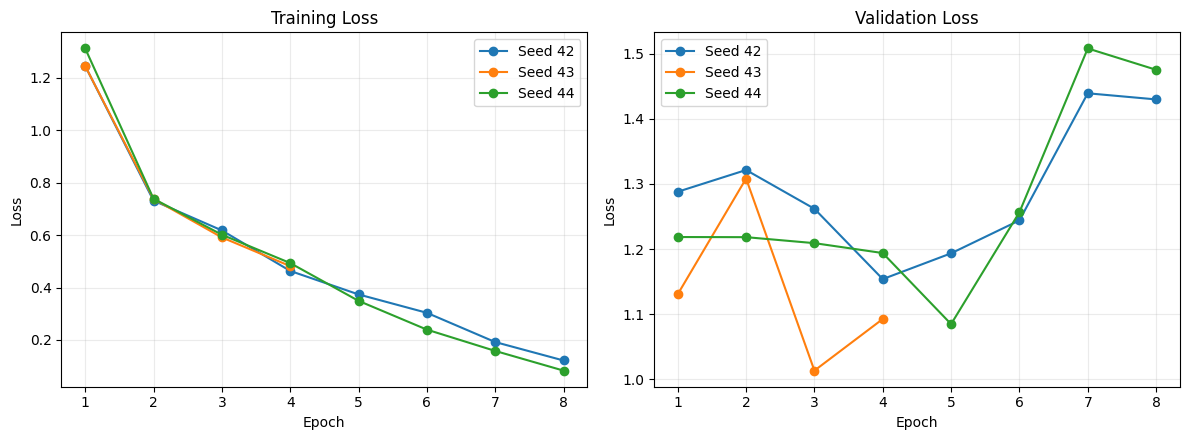

In [27]:
# Plot: training and validation loss
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for seed, h in sorted(run_histories.items()):
    epochs = range(1, len(h["train_loss"]) + 1)

    axes[0].plot(
        epochs, h["train_loss"],
        marker="o", label=f"Seed {seed}"
    )

    axes[1].plot(
        epochs, h["val_loss"],
        marker="o", label=f"Seed {seed}"
    )

for ax, title in zip(
    axes, ["Training Loss", "Validation Loss"]
):
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

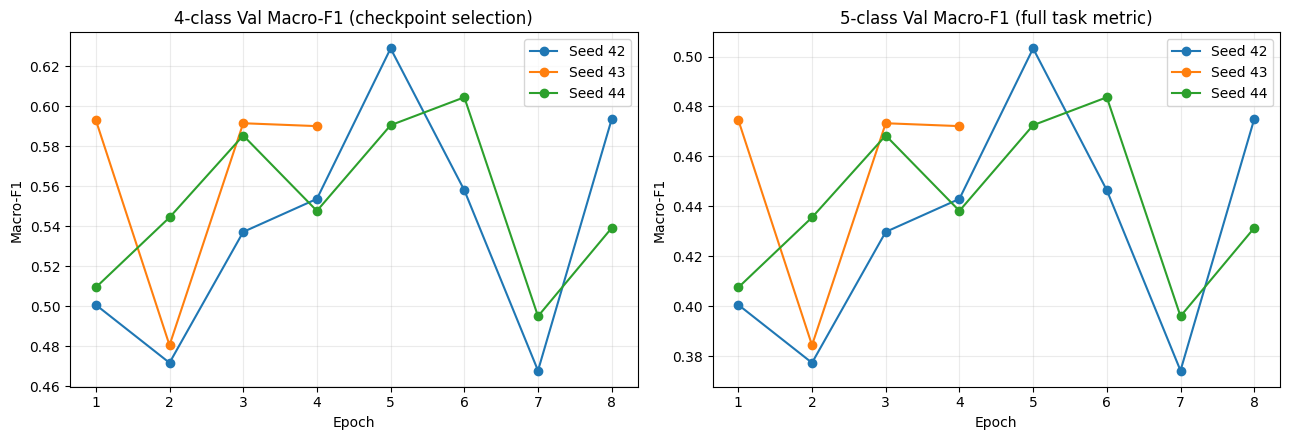

In [28]:
# Plot four-class selection F1 and five-class reporting F1 by epoch.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for seed, h in sorted(run_histories.items()):
    epochs = range(1, len(h["val_selection_f1_4"]) + 1)
    axes[0].plot(epochs, h["val_selection_f1_4"], marker="o", label=f"Seed {seed}")
    axes[1].plot(epochs, h["val_macro_f1"], marker="o", label=f"Seed {seed}")
axes[0].set_title("4-class Val Macro-F1 (checkpoint selection)")
axes[1].set_title("5-class Val Macro-F1 (full task metric)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Macro-F1")
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [29]:
# Select a trained seed for detailed Test diagnostics.
# Load its saved best-validation checkpoint.
DIAGNOSTIC_SEED = 42  # Detailed diagnostic seed
DIAGNOSTIC_PATH = runs_df.set_index("seed").loc[DIAGNOSTIC_SEED, "checkpoint"]
model = InteractionAwareBERT(
    MODEL_NAME, num_labels=5,
    use_interaction=USE_INTERACTION, use_spread=USE_SPREAD
).to(device)
model.load_state_dict(torch.load(DIAGNOSTIC_PATH, map_location=device, weights_only=True))
model.eval()
print(f"Diagnostics: seed {DIAGNOSTIC_SEED}, checkpoint {DIAGNOSTIC_PATH}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Diagnostics: seed 42, checkpoint best_interaction_1_spread_1_original_eval_seed42.pt


In [30]:
def get_predictions(model, data_loader):
    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for batch in data_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            document_mask = batch["document_mask"].to(device)
            labels = batch["label"].to(device)

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                document_mask=document_mask
            )

            predictions = torch.argmax(logits, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    return all_labels, all_predictions

In [31]:
# DIAGNOSTIC: seed selected by DIAGNOSTIC_SEED (seed 42)
train_true, train_pred = get_predictions(model, train_loader)

train_accuracy = accuracy_score(train_true, train_pred)
train_macro_f1 = f1_score(
    train_true,
    train_pred,
    average="macro",
    zero_division=0
)

print("Train Accuracy:", round(train_accuracy, 4))
print("Train Macro-F1:", round(train_macro_f1, 4))

print(
    classification_report(
        train_true,
        train_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No Conflict",
            "Complementary",
            "Conflicting Opinions",
            "Outdated",
            "Misinformation"
        ],
        zero_division=0
    )
)

Train Accuracy: 0.9127
Train Macro-F1: 0.9096
                      precision    recall  f1-score   support

         No Conflict       0.98      0.81      0.89       112
       Complementary       0.98      0.81      0.89        80
Conflicting Opinions       0.70      1.00      0.82        80
            Outdated       0.99      0.94      0.96        96
      Misinformation       0.97      1.00      0.98       113

            accuracy                           0.91       481
           macro avg       0.92      0.91      0.91       481
        weighted avg       0.93      0.91      0.91       481



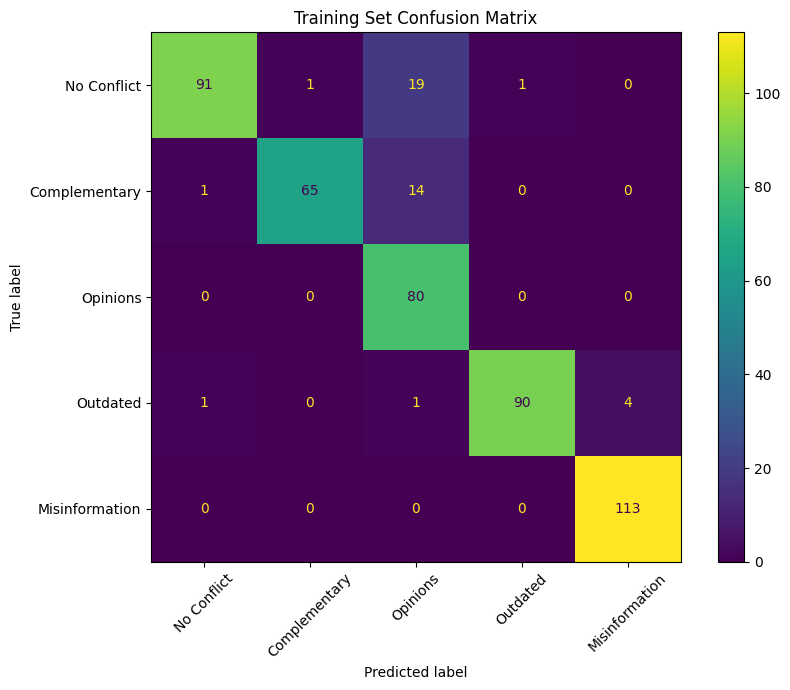

In [32]:
# DIAGNOSTIC: seed selected by DIAGNOSTIC_SEED (seed 42)
train_cm = confusion_matrix(
    train_true,
    train_pred,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=train_cm,
    display_labels=[
        "No Conflict",
        "Complementary",
        "Opinions",
        "Outdated",
        "Misinformation"
    ]
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45)

plt.title("Training Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [33]:
# DIAGNOSTIC: seed selected by DIAGNOSTIC_SEED (seed 42)
val_true, val_pred = get_predictions(model, val_loader)

val_accuracy = accuracy_score(val_true, val_pred)
val_macro_f1 = f1_score(
    val_true,
    val_pred,
    average="macro",
    zero_division=0
)

print("Validation Accuracy:", round(val_accuracy, 4))
print("Validation 5-class Macro-F1:", round(val_macro_f1, 4))
print("Validation 4-class Macro-F1 (selection):", round(four_class_macro_f1(val_true, val_pred), 4))

print(
    classification_report(
        val_true,
        val_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No Conflict",
            "Complementary",
            "Conflicting Opinions",
            "Outdated",
            "Misinformation"
        ],
        zero_division=0
    )
)

Validation Accuracy: 0.6324
Validation 5-class Macro-F1: 0.5032
Validation 4-class Macro-F1 (selection): 0.629
                      precision    recall  f1-score   support

         No Conflict       0.54      0.58      0.56        24
       Complementary       0.77      0.59      0.67        17
Conflicting Opinions       0.71      0.88      0.79        17
            Outdated       0.57      0.44      0.50         9
      Misinformation       0.00      0.00      0.00         1

            accuracy                           0.63        68
           macro avg       0.52      0.50      0.50        68
        weighted avg       0.64      0.63      0.63        68



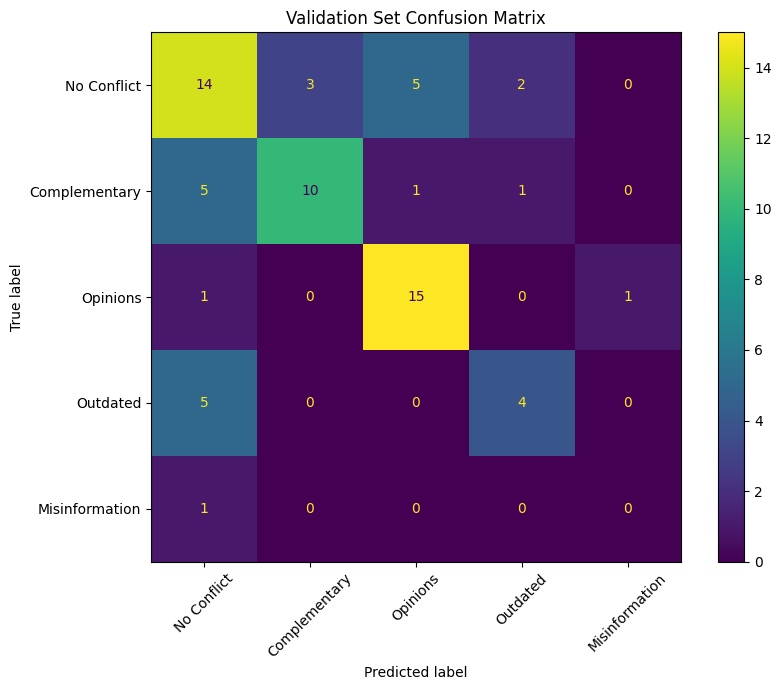

In [34]:
# DIAGNOSTIC: seed selected by DIAGNOSTIC_SEED (seed 42)
val_cm = confusion_matrix(
    val_true,
    val_pred,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=val_cm,
    display_labels=[
        "No Conflict",
        "Complementary",
        "Opinions",
        "Outdated",
        "Misinformation"
    ]
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45)

plt.title("Validation Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [35]:
# DIAGNOSTIC: seed selected by DIAGNOSTIC_SEED (seed 42)
# Internal test evaluation
test_loss, test_accuracy, test_macro_f1, y_true, y_pred = evaluate_model(model, test_loader)
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print("Test 5-class Macro-F1:", round(test_macro_f1, 4))
print("Test 4-class Macro-F1 (auxiliary):", round(four_class_macro_f1(y_true, y_pred), 4))


Test Loss: 1.1378
Test Accuracy: 0.6528
Test 5-class Macro-F1: 0.5327
Test 4-class Macro-F1 (auxiliary): 0.6659


In [36]:
# DIAGNOSTIC: seed selected by DIAGNOSTIC_SEED (seed 42)
# Per-class precision, recall and F1
target_names = [id2label[i] for i in range(5)]
print(classification_report(y_true, y_pred, labels=[0, 1, 2, 3, 4], target_names=target_names, zero_division=0))


                      precision    recall  f1-score   support

         No Conflict       0.68      0.68      0.68        25
       Complementary       0.73      0.44      0.55        18
Conflicting Opinions       0.65      0.83      0.73        18
            Outdated       0.70      0.70      0.70        10
      Misinformation       0.00      0.00      0.00         1

            accuracy                           0.65        72
           macro avg       0.55      0.53      0.53        72
        weighted avg       0.68      0.65      0.65        72



[[17  1  4  1  2]
 [ 3  8  4  2  1]
 [ 2  1 15  0  0]
 [ 2  1  0  7  0]
 [ 1  0  0  0  0]]


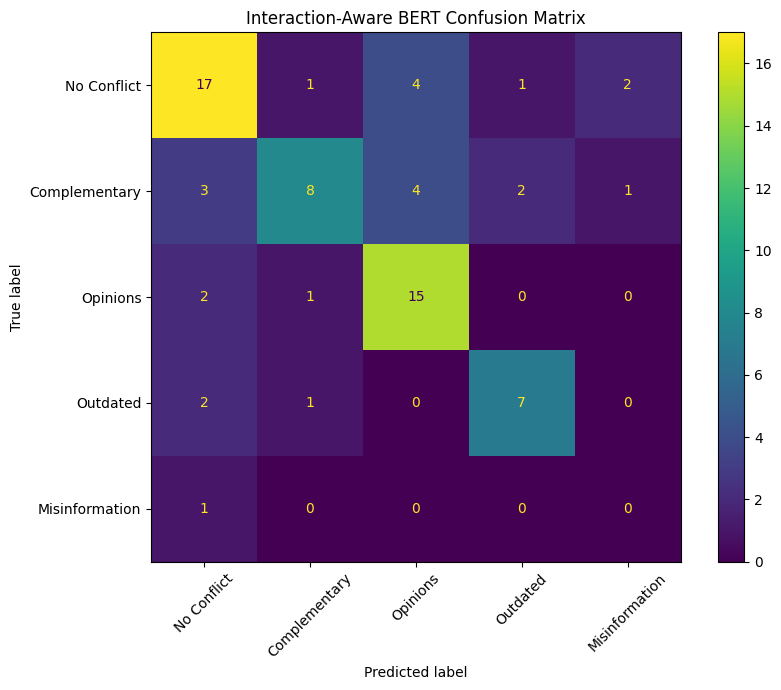

In [37]:
# DIAGNOSTIC: seed selected by DIAGNOSTIC_SEED (seed 42)
# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4])
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Conflict", "Complementary", "Opinions", "Outdated", "Misinformation"])
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45)
plt.title("Interaction-Aware BERT Confusion Matrix")
plt.tight_layout()
plt.show()


In [38]:
# DIAGNOSTIC: seed selected by DIAGNOSTIC_SEED (seed 42)
# Error analysis
results_df = test_df.copy()
results_df["prediction"] = y_pred
results_df["true_name"] = results_df["label"].map(id2label)
results_df["predicted_name"] = results_df["prediction"].map(id2label)
wrong_predictions = results_df[results_df["label"] != results_df["prediction"]].copy()

print("Number of wrong predictions:", len(wrong_predictions))
display(wrong_predictions[["question", "true_name", "predicted_name"]].head(10))


Number of wrong predictions: 25


,question,true_name,predicted_name
0,when was coffee first made into a drink?,Complementary,Conflicting Opinions
1,Where did the expression a bridge too far come...,Misinformation,No Conflict
5,How many cities in india has metro train?,Complementary,Outdated
12,Does the Y chromosome determine only the male ...,Complementary,Conflicting Opinions
13,Can the 'big bang' theory and creationism coex...,No Conflict,Conflicting Opinions
17,Are tax cuts beneficial for the economy?,Complementary,Conflicting Opinions
19,Are the brains of men and women wired differen...,No Conflict,Conflicting Opinions
25,who was the last person executed,Outdated,Complementary
26,what is the most obese province,Complementary,Outdated
31,who was the president during 1971 war,Complementary,No Conflict


## 4. Validation diagnostics across training seeds

Load the best saved checkpoint for each seed and calculate validation-set confusion matrices and per-class scores. This section performs inference only; the training checkpoints remain unchanged. Single-seed plots above use `DIAGNOSTIC_SEED = 42`.


In [39]:
# Compute per-seed validation confusion matrices and class metrics from checkpoints
per_class_rows = []
for seed in TRAIN_SEEDS:
    path = runs_df.set_index("seed").loc[seed, "checkpoint"]
    diagnostic_model = InteractionAwareBERT(
        MODEL_NAME, num_labels=5,
        use_interaction=USE_INTERACTION, use_spread=USE_SPREAD
    ).to(device)
    diagnostic_model.load_state_dict(
        torch.load(path, map_location=device, weights_only=True)
    )
    true, pred = get_predictions(diagnostic_model, val_loader)
    report = classification_report(
        true, pred, labels=list(range(5)),
        target_names=[id2label[i] for i in range(5)],
        output_dict=True, zero_division=0
    )
    for label in [id2label[i] for i in range(5)]:
        per_class_rows.append({
            "seed": seed, "class": label,
            "precision": report[label]["precision"],
            "recall": report[label]["recall"],
            "f1": report[label]["f1-score"],
            "support": report[label]["support"]
        })
    print(f"\nSeed {seed}: validation confusion matrix")
    print(confusion_matrix(true, pred, labels=list(range(5))))
    del diagnostic_model
per_class_df = pd.DataFrame(per_class_rows)
display(per_class_df.pivot(index="class", columns="seed", values="f1").round(3))
per_class_df.to_csv(f"{MODEL_TAG}_three_seed_validation_per_class.csv", index=False)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Seed 42: validation confusion matrix
[[14  3  5  2  0]
 [ 5 10  1  1  0]
 [ 1  0 15  0  1]
 [ 5  0  0  4  0]
 [ 1  0  0  0  0]]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Seed 43: validation confusion matrix
[[10  2  5  7  0]
 [ 3 13  1  0  0]
 [ 1  0 14  1  1]
 [ 3  2  0  4  0]
 [ 0  0  0  1  0]]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Seed 44: validation confusion matrix
[[14  3  5  2  0]
 [ 7  9  1  0  0]
 [ 2  1 14  0  0]
 [ 5  0  0  4  0]
 [ 1  0  0  0  0]]


seed,42,43,44
class,,,
Complementary,0.667,0.765,0.600
Conflicting Opinions,0.789,0.757,0.757
Misinformation,0.000,0.000,0.000
No Conflict,0.560,0.488,0.528
Outdated,0.500,0.364,0.533
